In [43]:
#!/usr/bin/python
# updated DBR 06/2026 #
# updated for JEM 10/12/2026 #

import numpy as np
import pandas as pd
import os
import scipy.optimize as opt #for power law fitting
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

import warnings
warnings.filterwarnings(action='once')

pd.set_option('display.max_rows', None)  # Show all rows
pd.set_option('display.max_columns', None)  # Show all columns
pd.set_option('display.width', None)  # Adjust width to avoid wrapping
pd.set_option('display.max_colwidth', None)  # Show full content in each column

In [44]:
#The clearance of HepB antigen at baseline before intervention
#The clearance rate at equilibrium after antibody is infused
#Relationship between Ag and antibody levels
#Antibody concentration required to maintain suppression vs. Ag concentration

In [45]:
#data
df_d = pd.read_excel('HBsAg_mAb19_long.xlsx')

df_d['dose'] = df_d['dose'].astype(int)

#update a little to add colors and only pick treated patients for the next steps

cmap = dict(zip([0, 1, 3, 10, 30], ['tab:gray', '#E39C4C', '#5794F1', '#D84E34', '#BF8BF0']))
#cmap = dict(zip(['0', '1', '3', '10', '30'], ['tab:gray', 'tab:green', 'tab:orange', 'tab:red', 'tab:blue']))

df_d['cz'] = df_d['dose'].map(cmap)
df_dtx = df_d[df_d['dose']>0]


df_d.head()


,participant,time,HBsAg,mAb19,dose,mAb19_cens,cz
0,102,-5,2999,1,0,0,tab:gray
1,102,0,2386,2,0,0,tab:gray
2,102,0,2903,1,0,1,tab:gray
3,102,0,2639,1,0,1,tab:gray
4,102,1,3560,2,0,0,tab:gray


In [46]:
#loop through models and check AIC etc

#get models

mnames = [f for f in os.listdir() if f.endswith(".mlxtran")]
mnames = [f.split('.')[0] for f in mnames] 

#mnames = ['mlx-simplefinal','mlx-satAfinalmore4']

#run monolix files again!!?
#mlxdir='/Applications/MonolixSuite2021R1.app/Contents/Resources/monolixSuite/lib/'
#modeldir='/Users/danielreeves/Dropbox/SCIENCE/_ongoing/HOPE2-charline/monolix2/'
#os.system(mlxdir + 'monolix --no-gui -p ' + modeldir + 'template.mlxtran')

#compare monolix model output (likelihood and AIC etc)

dfl=[]
for im,mn in enumerate(mnames):
    LLdf = pd.read_csv(mn+'/LogLikelihood/logLikelihood.txt')
    
    sn = mn.split('-')[1] #short name for model
    dfl.append([mn,sn,LLdf.iloc[0,1],LLdf.iloc[1,1],LLdf.iloc[2,1],LLdf.iloc[3,1]])
    
comp_df = pd.DataFrame(dfl,columns=['model_name','short_name','-2LL','AIC','BIC','BICc'])

sorted_df = comp_df.sort_values(by='AIC').round(1)

#sorted_df['total N']=(sorted_df['AIC']-sorted_df['-2LL'])/2 #use AIC to back calculate the number of parameters estimated
sorted_df['ΔLL']=sorted_df['-2LL']-sorted_df['-2LL'].iloc[0]
sorted_df['ΔAIC']=sorted_df['AIC']-sorted_df['AIC'].iloc[0]
sorted_df['ΔBICc']=sorted_df['BICc']-sorted_df['BICc'].iloc[0]

outdf=sorted_df[['short_name', 'ΔLL', 'ΔAIC', 'ΔBICc']]

pd.set_option('display.float_format', '{:.0f}'.format)

print(outdf.round(0).to_string(index=False))

        short_name  ΔLL  ΔAIC  ΔBICc
 satAfinalmoresatS    0     0      0
    satAfinalmore4   96   104    111
         satAfinal  112   112    115
       satAfinal_2  115   113    115
    satAfinalmore3  141   145    147
    satAfinalmore5  151   159    165
        satASfinal  290   296    310
     satAfinalmore 2278  2276   2275
satAfinalmoresatS2 2296  2296   2297
       simplefinal 4491  4493   4494


In [47]:
#print out the values from best model

#mn = 'mlx-satAfinalmoresatS'    
mn = 'mlx-satAfinalmore4'    

pdf = pd.read_csv(mn+'/IndividualParameters/estimatedIndividualParameters.txt')

for pzi in ['Dp_mode','Ax_mode','g_mode','psi_mode']:
    param = pdf[pzi].values

    median = np.median(param)
    q1, q3 = np.percentile(param, [25, 75])
    iqr = q3 - q1


    print(pzi,f"median = {median:.3f}",f"  ({q1:.3f}, {q3:.3f})")

Dp_mode median = 923.551   (348.187, 1289.462)
Ax_mode median = 18.374   (10.065, 40.898)
g_mode median = 0.342   (0.311, 0.447)
psi_mode median = 4.032   (2.324, 4.838)


In [48]:
#look at population mean and random effects

pdfpop = pd.read_csv(mn+'/populationParameters.txt', index_col='parameter')

#the styler has to be the last line of the cell, or the {:.0f} display setting above rounds everything
pdfpop.style.format('{:.5g}', na_rep='')


,value,CV,se_lin,rse_lin,P2.5_lin,P97.5_lin
parameter,,,,,,
Dp_pop,751.56,,350.68,46.66,335.92,1681.5
g_pop,0.36858,,0.15402,41.787,0.30047,0.78213
psi_pop,4.5471,,1.6648,36.612,2.3524,8.7894
Ax_pop,18.466,,6.3434,34.352,9.8952,34.46
hA_pop,10,,,,,
omega_Dp,1.6424,372.08,0.30285,18.439,1.1543,2.3371
omega_g,4.0855,40.123,3.0102,73.68,1.326,12.587
omega_psi,1.1454,164.72,0.22469,19.617,0.78792,1.6651
omega_Ax,1.1436,164.26,0.23056,20.161,0.77901,1.6789


In [49]:
#half-lives

for pzi in ['g_mode','psi_mode']:
    param = np.log(2)/pdf[pzi].values

    median = np.median(param)
    q1, q3 = np.percentile(param, [25, 75])
    iqr = q3 - q1


    print('half-life',pzi,f"median = {median:.3f}",f"  ({q1:.3f}, {q3:.3f})")

half-life g_mode median = 2.026   (1.552, 2.229)
half-life psi_mode median = 0.172   (0.143, 0.298)


<Axes: xlabel='dose', ylabel='g_mode'>

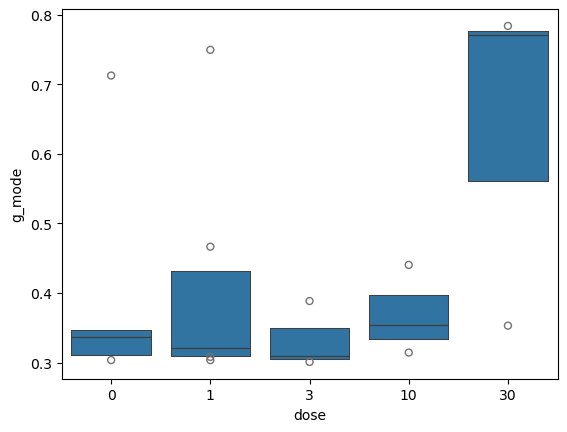

In [50]:
sns.boxenplot(data=pdf, x='dose', y='g_mode')

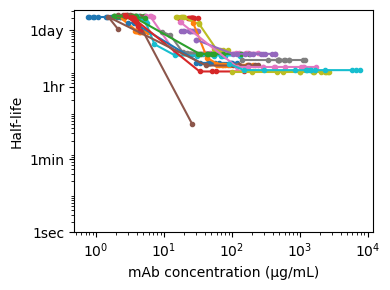

In [51]:
plt.figure(figsize=(4,3))

outkl=[]
for idd,d in enumerate(df_d['dose'].unique()):

    tdf1=df_d[df_d['dose']==d]

    for ip,p in enumerate(tdf1['participant'].unique()):
        
        tdfd = df_d[df_d['participant']==p][['dose','time','HBsAg','mAb19']].dropna()

        #Index(['participant', 'time', 'HBsAg', 'mAb19', 'dose', 'mAb19_cens', 'cz'], dtype='object')

        tdfp = pdf[pdf['id']==p]

        gamma = tdfp['g_mode'].iloc[0]
        psi = tdfp['psi_mode'].iloc[0]
        Ax = tdfp['Ax_mode'].iloc[0]
        hA = tdfp['hA_mode'].iloc[0]
        #Sx = tdfp['Sx_mode'].iloc[0]
        #hS = tdfp['hS_mode'].iloc[0]

        At = tdfd['mAb19'].values+0.1
        St = tdfd['HBsAg'].values
        
        nuA = 1/(1 + (Ax/At)**hA)
        #nuS = 1/(1 + (Sx/St)**hS)

        killrate = (psi*nuA + gamma)
        totalk = (psi*nuA+gamma)*St

        tt=tdfd['time'].values

        #plt.plot(At,np.log(2)/killrate,label=p,marker='.')
        plt.plot(At[1:],np.log(2)/killrate[1:],label=p,marker='.')

        for itt in range(len(At)):
            outkl.append([At[itt],St[itt],np.log(2)/killrate[itt]])

plt.loglog()
plt.yticks([1,1/24,1/(24*60),1/(24*60*60)],['1day','1hr','1min','1sec'])
plt.ylabel('Half-life')
plt.xlabel('mAb concentration (µg/mL)')
plt.tight_layout()
#plt.savefig('figures/half-lives-vsAt.svg')


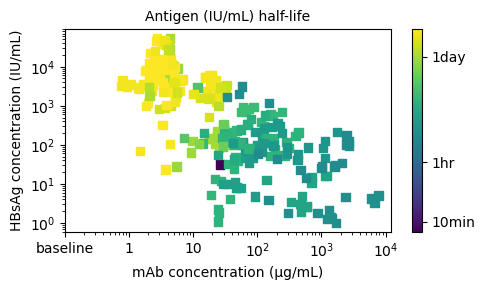

In [52]:
outka = np.array(outkl)

plt.figure(figsize=(5,3))
plt.scatter(outka[:,0],outka[:,1],c=np.log10(outka[:,2]),marker='s')
plt.loglog()

cbar = plt.colorbar(ticks=np.log10([7, 1,1/24,10/(24*60),1/(24*60*60)]))

cbar.set_ticklabels(['1wk','1day','1hr','10min','1sec'])
plt.xticks([0.1,1,10,100,1000,1e4],['baseline','1','10',r'10$^2$',r'10$^3$',r'10$^4$'])
plt.title('Antigen (IU/mL) half-life',fontsize=10)
plt.xlabel('mAb concentration (µg/mL)')
plt.ylabel('HBsAg concentration (IU/mL)')
plt.tight_layout()
#plt.savefig('figures/half-lives-vsAtSt.svg')

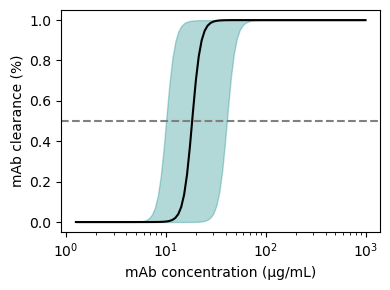

In [53]:
At = 10**np.linspace(0.1,3,100)

plt.figure(figsize=(4,3))

Ax = pdf['Ax_mode'].median()

Axl = np.percentile(pdf['Ax_mode'] ,25)
Axu = np.percentile(pdf['Ax_mode'] ,75)

plt.semilogx(At, 1/(1 + (Ax/At)**hA),color='k')
plt.fill_between(At,1/(1 + (Axl/At)**hA),1/(1 + (Axu/At)**hA),color='teal',alpha=0.3)
plt.axhline(0.5,color='gray',ls='--')

plt.xlabel('mAb concentration (µg/mL)')
plt.ylabel('mAb clearance (%)')

plt.tight_layout()
plt.savefig('EC50.svg')


In [54]:
# lower equilibrium code
def find_eq_midpoint(values, drop_thresh, flat_thresh):

    baseline = values[0]
    eq_idx = []
    i = 1

    while i < len(values):
        if baseline - values[i] >= drop_thresh:
            eq_idx.append(i)
            if abs(values[i] - values[eq_idx[0]]) > flat_thresh:
                eq_idx = []
        i += 1

    if len(eq_idx) < 2: #has to be 2 eq time points
        return 0

    return int((eq_idx[0] + eq_idx[-1]) // 2)


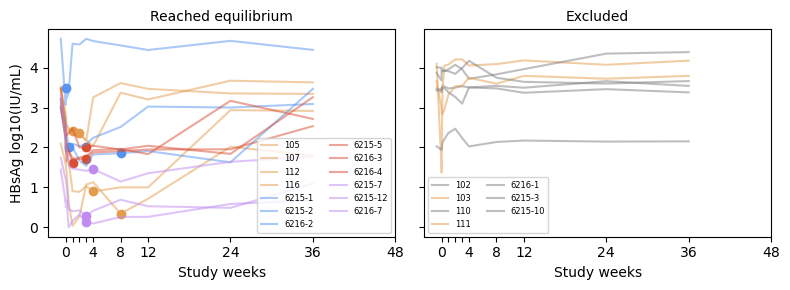

In [55]:
# For each patient, identify a lower equilibrium period:
# ≥2 consecutive timepoints where HBsAg < baseline AND slope is flat (|Δlog10S / Δt| < flat_thresh)
# Half-life is calculated at the midpoint of that window.

ddt = 1 #drop threshold in log10 units
dft = 0.5 #flat threshold in log10 units

#get list of pids that have "equilibrium" and get the time point for that

fig,axs=plt.subplots(1,2,sharex=True,sharey=True,figsize=(8,3))

eqpl=[]; eqidxl=[]
for p in df_d['participant'].unique():
    
    tdfd = df_d[df_d['participant'] == p][['HBsAg','time','cz']].dropna()

    St    = np.log10(tdfd['HBsAg'].values)
    Stb   = St-St[0] 
    tt    = tdfd['time'].values

    idxeq = find_eq_midpoint(St,ddt,dft)

    if idxeq:
        eqpl.append(p)
        eqidxl.append(idxeq)

        axs[0].plot(tt/7,St,label=p,alpha=0.5,color=tdfd['cz'].iloc[0])
        axs[0].scatter(tt[idxeq]/7,St[idxeq],color=tdfd['cz'].iloc[0])
        axs[0].legend(fontsize=6,ncol=2)

    else:
        axs[1].plot(tt/7,St,label=p,alpha=0.5,color=tdfd['cz'].iloc[0])
        axs[1].legend(fontsize=6,ncol=2)

axs[0].set_title('Reached equilibrium',fontsize=10)
axs[1].set_title('Excluded',fontsize=10)

#axs[0].set_ylim([-1,5])
axs[0].set_xlabel('Study weeks')
axs[1].set_xlabel('Study weeks')
axs[0].set_ylabel('HBsAg log10(IU/mL)')
axs[0].set_xticks([0,1,2,3,4,8,12,24,36,48])
axs[0].set_xticklabels([0,'','','',4,8,12,24,36,48])

plt.tight_layout()
plt.savefig('figures/midpointeq.svg')


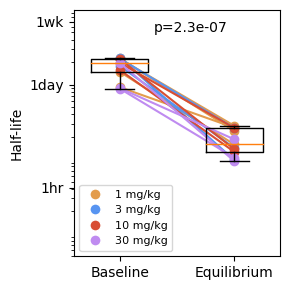

In [56]:
#make a simple calculation based on maximum difference

hlequil=[]; hlbasel=[]
plt.figure(figsize=(3,3))

for ip,p in enumerate(eqpl):
#for p in df_dtx['participant'].unique():
    
    tdfd = df_dtx[df_dtx['participant'] == p][['HBsAg','time','cz','mAb19']]

    tt = tdfd['time'].values
    St = tdfd['HBsAg'].values
    Stb = St[0]/St[eqidxl[ip]]
    
    At = tdfd['mAb19'].values
    Atb = At[eqidxl[ip]]
    #Stb = St[0]/np.min(St)

    if mn == 'mlx-satAfinalmoresatS':
        g,psi,A50,hA,S50,hS = pdf[pdf['id'] == p][['g_mode','psi_mode','Ax_mode','hA_mode','Sx_mode','hS_mode']].values[0]
        kA = psi/Stb*(Atb**hA)/(A50**hA + Atb**hA)*(Stb**hS)/(S50**hS + Stb**hS) #instantaneous clearance rate due to antibody at equilibrium,  need to divide by S for units

    elif 'mlx-satAfinalmore' in mn:
        g,psi,A50,hA = pdf[pdf['id'] == p][['g_mode','psi_mode','Ax_mode','hA_mode']].values[0]
        kA = psi*(Atb**hA)/(A50**hA + Atb**hA) #instantaneous clearance rate due to antibody at equilibrium

    #kA = g*(Stb-1)
    
    hl0=np.log(2)/(g)
    hlb=np.log(2)/(g+kA)

    hlbasel.append(hl0)
    hlequil.append(hlb)

    #print(p,hl0,hlb)

    #simple plot
    plt.plot([1,2],[hl0,hlb],label=p,marker='o',color=tdfd['cz'].values[0])

plt.boxplot([hlbasel,hlequil],widths=0.5,showfliers=False)
#plt.legend(bbox_to_anchor=[1.1,1])

#U, pval = stats.mannwhitneyu(hlbasel, hlequil)#, alternative='one-sided')
T, pval = stats.ttest_rel(hlbasel, hlequil)#, alternative='one-sided')

plt.annotate('p='+str(np.round(pval,8)),[1.3,5])
plt.semilogy()
plt.ylabel('Half-life')
plt.yticks([7,1,1/24,1/(24*60)],['1wk','1day','1hr','1min'])
plt.ylim(0.005,10)
plt.xticks([1,2],['Baseline','Equilibrium'])
plt.xlim(0.6,2.4)

from matplotlib.lines import Line2D

handles = [Line2D([0], [0], marker='o', color='w', markerfacecolor=c, label=f'{d} mg/kg', markersize=8)
           for d, c in cmap.items() if d > 0]
plt.legend(handles=handles,fontsize=8, loc=3)

plt.tight_layout()
plt.savefig('halflife-summarysimple2.svg')


In [57]:
print('median half life',np.median(hlbasel)*24,'hours baseline to',np.median(hlequil)*24,'hours at equilibrium')

median half life 46.94290371704419 hours baseline to 3.7875317928001513 hours at equilibrium


In [58]:
foldchange=np.array(hlbasel)/np.array(hlequil)

print('median fold change:', np.median(foldchange), 'range (min, max):', np.min(foldchange), np.max(foldchange))

print('mean fold change:', np.mean(foldchange), 'range (5th,95th):', np.percentile(foldchange, [2.5, 97.5]))


median fold change: 9.391132843012338 range (min, max): 3.487019064281423 23.61045444665816
mean fold change: 11.156873439585357 range (5th,95th): [ 3.90134807 22.74795371]


In [59]:
#fold change per person: mean and sd over the Monolix conditional-distribution draws

sdf = pd.read_csv(mn+'/IndividualParameters/simulatedIndividualParameters.txt')

fcl=[]
for ip,p in enumerate(eqpl):

    tdfd = df_dtx[df_dtx['participant'] == p][['HBsAg','time','mAb19','dose']].dropna(subset=['HBsAg'])
    Atb = tdfd['mAb19'].values[eqidxl[ip]]

    ts = sdf[sdf['id']==p]
    fc = 1 + ts['psi']/ts['g']*(Atb**ts['hA'])/(ts['Ax']**ts['hA'] + Atb**ts['hA'])

    fcl.append([p, tdfd['dose'].iloc[0], foldchange[ip], fc.mean(), fc.std()])

fc_df = pd.DataFrame(fcl, columns=['id','dose','fold_mode','fold_mean','fold_sd'])

print(fc_df.to_string(index=False, float_format='%.1f'))
print('median fold change (n=%d): %.1f' % (len(fc_df), fc_df['fold_mode'].median()))

     id  dose  fold_mode  fold_mean  fold_sd
    105     1        7.9        8.0      0.5
    107     1        3.5        3.4      0.4
    112     1        9.4       10.0      0.8
    116     1        9.4        9.4      1.1
 6215-1     3       12.6       12.6      0.9
 6215-2     3        8.5        9.0      0.7
 6216-2     3       23.6       22.7      1.9
 6215-5    10        7.4        7.8      0.7
 6216-3    10       16.1       16.9      2.4
 6216-4    10       12.5       12.5      0.7
 6215-7    30        4.9        4.9      0.7
6215-12    30       20.7       21.3      2.3
 6216-7    30        8.4        9.1      0.6
median fold change (n=13): 9.4


In [60]:
#median including the 2 who never reached equilibrium (103, 111),
#evaluated at the mean equilibrium time of the others

teq = np.mean([df_dtx[df_dtx['participant']==p].dropna(subset=['HBsAg'])['time'].values[eqidxl[ip]] for ip,p in enumerate(eqpl)])

fc_all = list(foldchange)
for p in df_dtx['participant'].unique():
    if p not in eqpl:
        tdfd = df_dtx[df_dtx['participant'] == p][['time','mAb19']].dropna()
        Atb = np.interp(teq, tdfd['time'], tdfd['mAb19'])

        g,psi,A50,hA = pdf[pdf['id'] == p][['g_mode','psi_mode','Ax_mode','hA_mode']].values[0]
        fc_all.append(1 + psi/g*(Atb**hA)/(A50**hA + Atb**hA))
        print(p, 'mAb at day %.1f: %.1f ug/mL, fold change %.2f' % (teq, Atb, fc_all[-1]))

print('median fold change (n=%d): %.1f' % (len(fc_all), np.median(fc_all)))

103 mAb at day 21.8: 3.2 ug/mL, fold change 1.00
111 mAb at day 21.8: 17.8 ug/mL, fold change 1.00
median fold change (n=15): 8.5


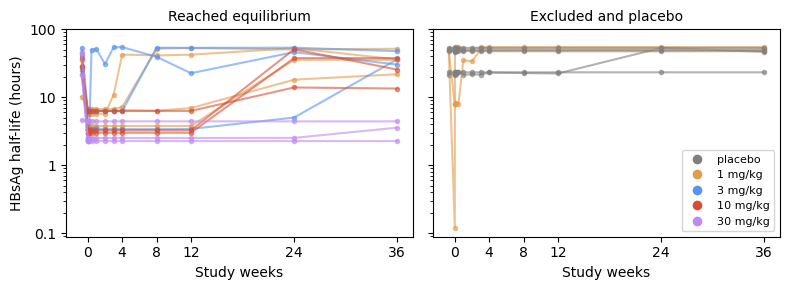

In [61]:
#HBsAg half-life over time, ln2/(g + psi*nuA(A(t))), all participants

fig,axs=plt.subplots(1,2,sharey=True,figsize=(8,3))

for p in df_d['participant'].unique():

    tdfd = df_d[df_d['participant'] == p][['time','mAb19','dose','cz']].dropna()
    g,psi,A50,hA = pdf[pdf['id'] == p][['g_mode','psi_mode','Ax_mode','hA_mode']].values[0]

    #hA=1
    At = tdfd['mAb19'].values+0.1
    hlt = np.log(2)/(g + psi/(1 + (A50/At)**hA))*24 #hours

    ax = axs[0] if p in eqpl else axs[1]
    ax.plot(tdfd['time']/7,hlt,marker='.',alpha=0.6,color=tdfd['cz'].iloc[0])

axs[0].set_title('Reached equilibrium',fontsize=10)
axs[1].set_title('Excluded and placebo',fontsize=10)
for ax in axs:
    ax.set_xlabel('Study weeks')
    ax.set_xticks([0,4,8,12,24,36])
axs[0].set_ylabel('HBsAg half-life (hours)')
plt.semilogy()
plt.yticks([0.1,1,10,100],['0.1','1','10','100'])

from matplotlib.lines import Line2D
handles = [Line2D([0], [0], marker='o', color='w', markerfacecolor=cmap[d], label=('placebo' if d==0 else f'{d} mg/kg'), markersize=8)
           for d in [0, 1, 3, 10, 30]]
axs[1].legend(handles=handles, fontsize=8, loc=4)

plt.tight_layout()
plt.savefig('figures/halflife-vs-time.svg')

mean (n=13): 11.2 (95% CI 7.9-14.4), median 9.4
mean (n=15): 9.8 (95% CI 6.5-13.1), median 8.5


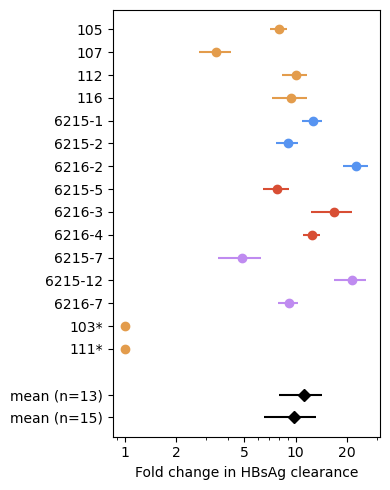

In [62]:
#forest plot: fold change per person (mean +/- sd over draws), and means with/without the 2 excluded

fl = fc_df[['id','dose','fold_mean','fold_sd']].values.tolist()

for p in df_dtx['participant'].unique():
    if p not in eqpl:
        tdfd = df_dtx[df_dtx['participant'] == p][['time','mAb19','dose']].dropna()
        Atb = np.interp(teq, tdfd['time'], tdfd['mAb19'])
        ts = sdf[sdf['id']==p]
        fc = 1 + ts['psi']/ts['g']*(Atb**ts['hA'])/(ts['Ax']**ts['hA'] + Atb**ts['hA'])
        fl.append([p+'*', tdfd['dose'].iloc[0], fc.mean(), fc.std()])

plt.figure(figsize=(4,5))

for i,(p,d,m,s) in enumerate(fl):
    plt.errorbar(m,i,xerr=1.96*s,marker='o',color=cmap[d],capsize=0)

for j,x in enumerate([foldchange, fc_all]):
    #lo,hi = stats.t.interval(0.95, len(x)-1, loc=np.mean(x), scale=stats.sem(x))

    mx = np.mean(x) #mean of the fold change
    lo=mx-1.96*stats.sem(x)
    hi=mx+1.96*stats.sem(x)

    plt.errorbar(mx,len(fl)+1+j,xerr=[[mx-lo],[hi-mx]],marker='D',color='k',capsize=0)
    
    print('mean (n=%d): %.1f (95%% CI %.1f-%.1f), median %.1f' % (len(x),mx,lo,hi,np.median(x)))

plt.yticks(list(range(len(fl)))+[len(fl)+1,len(fl)+2],[f[0] for f in fl]+['mean (n=13)','mean (n=15)'])
plt.gca().invert_yaxis()
plt.semilogx()
plt.xticks([1,2,5,10,20],['1','2','5','10','20'])
plt.xlabel('Fold change in HBsAg clearance')
plt.tight_layout()
plt.savefig('figures/forest-satAfinalmore4.svg')

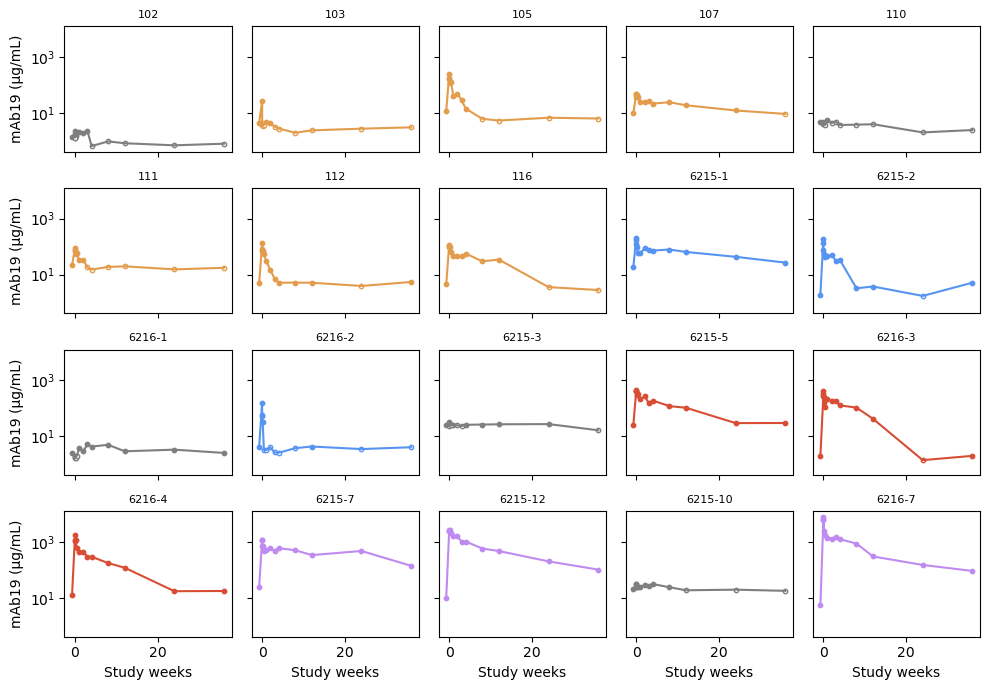

In [64]:
#PK: mAb19 data for each person (open circles = censored)

plist = df_d['participant'].unique()

fig,axs=plt.subplots(4,5,sharex=True,sharey=True,figsize=(10,7))

for ip,p in enumerate(plist):
    ax = axs.flat[ip]
    tdfd = df_d[df_d['participant'] == p][['time','mAb19','mAb19_cens','cz']].dropna()
    cens = tdfd['mAb19_cens']==1

    ax.plot(tdfd['time']/7,tdfd['mAb19'],color=tdfd['cz'].iloc[0])
    ax.scatter(tdfd['time'][~cens]/7,tdfd['mAb19'][~cens],color=tdfd['cz'].iloc[0],s=10)
    ax.scatter(tdfd['time'][cens]/7,tdfd['mAb19'][cens],facecolor='w',edgecolor=tdfd['cz'].iloc[0],s=10)
    ax.set_title(p,fontsize=8)

plt.semilogy()
for ax in axs[-1]: ax.set_xlabel('Study weeks')
for ax in axs[:,0]: ax.set_ylabel('mAb19 (µg/mL)')
plt.tight_layout()
plt.savefig('figures/PK-allpeople.svg')


In [ ]:
#HBsAg data and model fit (Monolix individual prediction, mode) for each person

prdf = pd.read_csv(mn+'/predictions.txt')
prdf['id'] = prdf['id'].astype(str)

fig,axs=plt.subplots(4,5,sharex=True,sharey=True,figsize=(8,4))

for ip,p in enumerate(plist):
    ax = axs.flat[ip]
    tpr = prdf[prdf['id'] == p]
    cz = df_d[df_d['participant'] == p]['cz'].iloc[0]

    ax.scatter(tpr['time']/7,tpr['HBsAg'],color=cz,s=10)
    ax.plot(tpr['time']/7,tpr['indivPred_mode'],color='k',lw=2,alpha=0.8)
    ax.annotate(p,[20,0.2],fontsize=8)

    #PK on the right axis
    tdfa = df_d[df_d['participant'] == p][['time','mAb19']].dropna()
    tax = ax.twinx()
    tax.plot(tdfa['time']/7,tdfa['mAb19'],color='gray',lw=1,ls='--')
    tax.set_yscale('log')
    tax.set_ylim(0.5,1e4)
    tax.set_yticks([1,100,1e4])
    if ip%5 < 4: tax.tick_params(labelright=False)

axs[0,0].set_yscale('log')
axs[0,0].set_ylim(0.1,1e6)
axs[0,0].set_xticks([0,4,8,12,24,36])

plt.subplots_adjust(hspace=0.4, wspace=0.3)
plt.tight_layout()
plt.subplots_adjust(left=0.08,right=0.92)
fig.text(0.01,0.5,'HBsAg (IU/mL)',rotation=90,va='center')
fig.text(0.985,0.5,'mAb19 (µg/mL), dashed',rotation=90,va='center')
plt.savefig('figures/HBsAg-fits-allpeople.svg')


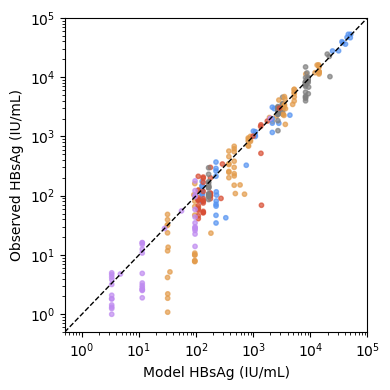

In [67]:
#model vs data, all people

plt.figure(figsize=(4,4))

cz = prdf['id'].map(dict(zip(df_d['participant'],df_d['cz'])))
plt.scatter(prdf['indivPred_mode'],prdf['HBsAg'],c=cz,s=10,alpha=0.7)

lims = [0.5,1e5]
plt.plot(lims,lims,color='k',ls='--',lw=1)
plt.loglog()
plt.xlim(lims); plt.ylim(lims)
plt.xlabel('Model HBsAg (IU/mL)')
plt.ylabel('Observed HBsAg (IU/mL)')
plt.tight_layout()
plt.savefig('figures/HBsAg-obs-vs-pred.svg')
